# Extraction and Exploratory Data Analysis

**Goal:** extract, explore, clean and transform a real retail dataset.

**Data:** Online Retail, UCI Machine Learning Repository. UK online gift shop, 01 Dec 2010 to 09 Dec 2011.

**Why:** the shop needs to know its best products, customers and countries, but the raw data has to be checked first.

```text
Raw Data
↓
Extraction
↓
Exploratory Data Analysis
↓
Cleaning
↓
Transformation
```

The raw data is only read and described in this section.

## Section 2: Imports

In [1]:
import hashlib
import os
import tempfile
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
if "VSCODE_PID" not in os.environ:
    pio.renderers.default = "plotly_mimetype"
print("pandas", pd.__version__)

pandas 3.0.2


## Section 3: Locate the Dataset

Looks for the zip next to the notebook, in a `data` folder, or in Downloads. The zip is only read. The extracted copy goes to a temp folder.

In [2]:
WORK_DIR = Path(tempfile.gettempdir()) / "online_retail_capstone"
RAW_DIR = WORK_DIR / "raw"
WORK_DIR.mkdir(exist_ok=True)
RAW_DIR.mkdir(exist_ok=True)


def find_project_dir():
    here = Path.cwd()
    for folder in [here, here / "notebooks", here.parent]:
        if (folder / "01_extraction_and_eda.ipynb").exists():
            return folder
    return here


PROJECT_DIR = find_project_dir()


def find_zip():
    base = PROJECT_DIR
    folders = [base, base / "data", base.parent, base.parent / "data", Path.cwd(), Path.cwd() / "data", Path.home() / "Downloads"]
    for folder in folders:
        if folder.is_dir():
            matches = sorted(folder.glob("online*retail*.zip"))
            if matches:
                return matches[0]
    raise FileNotFoundError("online+retail.zip was not found next to the notebooks, in a data folder or in Downloads")


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

In [3]:
zip_path = find_zip()
zip_hash = file_sha256(zip_path)
print("ZIP file     :", zip_path.name)
print("Size (MB)    :", round(zip_path.stat().st_size / 1024 ** 2, 2))
print("SHA-256      :", zip_hash)

ZIP file     : online+retail.zip
Size (MB)    : 22.62
SHA-256      : f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b


In [4]:
with zipfile.ZipFile(zip_path) as archive:
    archive_contents = pd.DataFrame(
        [{"file": item.filename, "size_mb": round(item.file_size / 1024 ** 2, 2)} for item in archive.infolist()]
    )
archive_contents

,file,size_mb
0,Online Retail.xlsx,22.62


In [5]:
with zipfile.ZipFile(zip_path) as archive:
    excel_members = [name for name in archive.namelist() if name.lower().endswith((".xlsx", ".xls"))]
    if not excel_members:
        raise FileNotFoundError("No Excel file found inside the ZIP archive")
    archive.extract(excel_members[0], RAW_DIR)

excel_path = RAW_DIR / excel_members[0]
print("Excel dataset:", excel_path.name)
print("Exists       :", excel_path.exists())
print("ZIP unchanged:", file_sha256(zip_path) == zip_hash)

Excel dataset: Online Retail.xlsx
Exists       : True
ZIP unchanged: True


## Section 4: Extraction

Load the Excel file into `raw_df`. Takes about a minute.

In [6]:
raw_df = pd.read_excel(excel_path)
print("Rows   :", f"{raw_df.shape[0]:,}")
print("Columns:", raw_df.shape[1])

Rows   : 541,909
Columns: 8


In [7]:
pd.DataFrame({"position": range(1, len(raw_df.columns) + 1), "column": raw_df.columns})

,position,column
0,1,InvoiceNo
1,2,StockCode
2,3,Description
3,4,Quantity
4,5,InvoiceDate
5,6,UnitPrice
6,7,CustomerID
7,8,Country


In [8]:
raw_df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [9]:
raw_df.tail(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541899,581587,22726,ALARM CLOCK BAKELIKE GREEN,4,2011-12-09 12:50:00,3.75,12680.0,France
541900,581587,22730,ALARM CLOCK BAKELIKE IVORY,4,2011-12-09 12:50:00,3.75,12680.0,France
541901,581587,22367,CHILDRENS APRON SPACEBOY DESIGN,8,2011-12-09 12:50:00,1.95,12680.0,France
541902,581587,22629,SPACEBOY LUNCH BOX,12,2011-12-09 12:50:00,1.95,12680.0,France
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,2011-12-09 12:50:00,4.15,12680.0,France
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [10]:
raw_df.dtypes.rename("dtype").to_frame()

,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str


## Section 5: Basic EDA

In [11]:
raw_df.shape

(541909, 8)

In [12]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [13]:
raw_df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [14]:
raw_df[["InvoiceNo", "StockCode", "Description", "Country"]].astype(str).describe()

,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [15]:
unique_values = raw_df.nunique(dropna=True).rename("unique_values").to_frame()
unique_values

,unique_values
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


In [16]:
invoice_text = raw_df["InvoiceNo"].astype(str)
stock_text = raw_df["StockCode"].astype(str)

key_counts = pd.DataFrame(
    {
        "metric": ["Transaction lines", "Unique invoices", "Unique customers", "Unique products (StockCode)", "Unique countries"],
        "value": [len(raw_df), invoice_text.nunique(), raw_df["CustomerID"].nunique(), stock_text.nunique(), raw_df["Country"].nunique()],
    }
)
key_counts

,metric,value
0,Transaction lines,541909
1,Unique invoices,25900
2,Unique customers,4372
3,Unique products (StockCode),4070
4,Unique countries,38


## Section 6: Data Quality Investigation

Only checking for problems here. Nothing is changed.

### 6.1 Missing values

In [17]:
missing_table = pd.DataFrame(
    {"missing_count": raw_df.isna().sum(), "missing_percent": (raw_df.isna().mean() * 100).round(2)}
)
missing_table

,missing_count,missing_percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


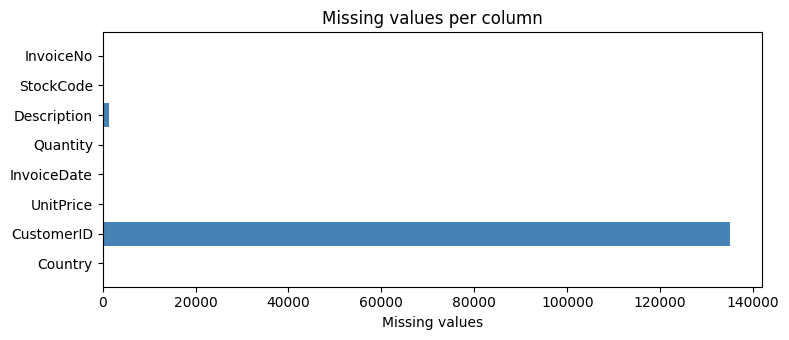

In [18]:
missing_counts = raw_df.isna().sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing_counts.index, missing_counts.values, color="steelblue")
ax.set_xlabel("Missing values")
ax.set_title("Missing values per column")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 6.2 Duplicate rows and invoice structure

In [19]:
duplicate_mask = raw_df.duplicated(keep=False)
duplicate_row_count = int(raw_df.duplicated().sum())
print("Fully duplicated rows (extra copies):", f"{duplicate_row_count:,}", f"({duplicate_row_count / len(raw_df) * 100:.2f}% of rows)")
raw_df[duplicate_mask].sort_values(["InvoiceNo", "StockCode"]).head(10)

Fully duplicated rows (extra copies): 5,268 (0.97% of rows)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [20]:
lines_per_invoice = raw_df.groupby(invoice_text).size()
invoice_customers = raw_df.groupby(invoice_text)["CustomerID"].nunique(dropna=False)
invoice_timestamps = raw_df.groupby(invoice_text)["InvoiceDate"].nunique()

invoice_structure = pd.DataFrame(
    {
        "check": [
            "Invoices",
            "Invoices with more than one line (expected, an invoice holds many products)",
            "Invoices linked to more than one CustomerID",
            "Invoices with more than one InvoiceDate value",
        ],
        "count": [len(lines_per_invoice), int((lines_per_invoice > 1).sum()), int((invoice_customers > 1).sum()), int((invoice_timestamps > 1).sum())],
    }
)
invoice_structure

,check,count
0,Invoices,25900
1,"Invoices with more than one line (expected, an...",20059
2,Invoices linked to more than one CustomerID,0
3,Invoices with more than one InvoiceDate value,43


In [21]:
lines_per_invoice.describe().to_frame("lines_per_invoice")

,lines_per_invoice
count,25900.000000
mean,20.923127
std,43.031334
min,1.000000
25%,2.000000
50%,10.000000
75%,23.000000
max,1114.000000


### 6.3 Quantity and price

In [22]:
quantity_issues = pd.DataFrame(
    {
        "check": ["Quantity equal to zero", "Quantity below zero", "UnitPrice equal to zero", "UnitPrice below zero"],
        "rows": [
            int((raw_df["Quantity"] == 0).sum()),
            int((raw_df["Quantity"] < 0).sum()),
            int((raw_df["UnitPrice"] == 0).sum()),
            int((raw_df["UnitPrice"] < 0).sum()),
        ],
    }
)
quantity_issues["percent_of_rows"] = (quantity_issues["rows"] / len(raw_df) * 100).round(3)
quantity_issues

,check,rows,percent_of_rows
0,Quantity equal to zero,0,0.000
1,Quantity below zero,10624,1.960
2,UnitPrice equal to zero,2515,0.464
3,UnitPrice below zero,2,0.000


In [23]:
raw_df[raw_df["Quantity"] < 0].head(8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom


In [24]:
raw_df[raw_df["UnitPrice"] <= 0].head(8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom


In [25]:
extreme_rows = raw_df[raw_df["Quantity"].abs() >= 10000]
print("Rows with absolute quantity of 10,000 or more:", len(extreme_rows))
extreme_rows

Rows with absolute quantity of 10,000 or more: 5


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


### 6.4 Missing CustomerID and missing descriptions

In [26]:
missing_customer = raw_df["CustomerID"].isna()
missing_description = raw_df["Description"].isna()
raw_revenue_line = raw_df["Quantity"] * raw_df["UnitPrice"]

customer_issue_table = pd.DataFrame(
    {
        "check": [
            "Rows without CustomerID",
            "Rows without Description",
            "Rows missing both",
            "Rows without Description that have a CustomerID",
            "Unit price zero among rows without Description",
        ],
        "rows": [
            int(missing_customer.sum()),
            int(missing_description.sum()),
            int((missing_customer & missing_description).sum()),
            int((~missing_customer & missing_description).sum()),
            int((missing_description & (raw_df["UnitPrice"] == 0)).sum()),
        ],
    }
)
customer_issue_table

,check,rows
0,Rows without CustomerID,135080
1,Rows without Description,1454
2,Rows missing both,1454
3,Rows without Description that have a CustomerID,0
4,Unit price zero among rows without Description,1454


In [27]:
anonymous_revenue = raw_revenue_line[missing_customer].sum()
total_raw_revenue = raw_revenue_line.sum()
print("Quantity x UnitPrice on rows without CustomerID:", f"{anonymous_revenue:,.2f}")
print("Share of the raw revenue total                 :", f"{anonymous_revenue / total_raw_revenue * 100:.1f}%")

Quantity x UnitPrice on rows without CustomerID: 1,447,682.12
Share of the raw revenue total                 : 14.9%


### 6.5 Cancelled invoices

In [28]:
cancelled_mask = invoice_text.str.startswith("C")
adjustment_mask = invoice_text.str.startswith("A")
negative_not_cancelled = (raw_df["Quantity"] < 0) & ~cancelled_mask

cancel_table = pd.DataFrame(
    {
        "check": [
            "Lines on invoices starting with C (cancellations)",
            "Distinct cancelled invoices",
            "Lines on invoices starting with A",
            "Negative quantity lines that are not cancellations",
            "Cancelled lines with a positive quantity",
        ],
        "count": [
            int(cancelled_mask.sum()),
            int(invoice_text[cancelled_mask].nunique()),
            int(adjustment_mask.sum()),
            int(negative_not_cancelled.sum()),
            int((cancelled_mask & (raw_df["Quantity"] > 0)).sum()),
        ],
    }
)
cancel_table

,check,count
0,Lines on invoices starting with C (cancellations),9288
1,Distinct cancelled invoices,3836
2,Lines on invoices starting with A,3
3,Negative quantity lines that are not cancellat...,1336
4,Cancelled lines with a positive quantity,0


In [29]:
raw_df[cancelled_mask].head(6)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [30]:
raw_df[adjustment_mask]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


### 6.6 Date format and data types

In [31]:
date_summary = pd.DataFrame(
    {
        "check": ["dtype", "Missing dates", "Earliest invoice", "Latest invoice", "Distinct calendar days", "Rows with non-zero seconds"],
        "result": [
            str(raw_df["InvoiceDate"].dtype),
            int(raw_df["InvoiceDate"].isna().sum()),
            raw_df["InvoiceDate"].min(),
            raw_df["InvoiceDate"].max(),
            raw_df["InvoiceDate"].dt.normalize().nunique(),
            int((raw_df["InvoiceDate"].dt.second != 0).sum()),
        ],
    }
)
date_summary.astype(str)

,check,result
0,dtype,datetime64[us]
1,Missing dates,0
2,Earliest invoice,2010-12-01 08:26:00
3,Latest invoice,2011-12-09 12:50:00
4,Distinct calendar days,305
5,Rows with non-zero seconds,0


In [32]:
type_check = pd.DataFrame(
    {
        column: raw_df[column].map(lambda value: type(value).__name__).value_counts()
        for column in ["InvoiceNo", "StockCode", "CustomerID"]
    }
).fillna(0).astype(int)
type_check

,InvoiceNo,StockCode,CustomerID
float,0,0,541909
int,532618,487036,0
str,9291,54873,0


### 6.7 Unexpected values

In [33]:
product_pattern = stock_text.str.match(r"^\d{5}")
non_product_codes = (
    raw_df[~product_pattern]
    .assign(StockCode=stock_text[~product_pattern])
    .groupby("StockCode")
    .agg(lines=("StockCode", "size"), example_description=("Description", "first"))
    .sort_values("lines", ascending=False)
)
print("Distinct stock codes that do not start with a 5-digit product number:", len(non_product_codes))
non_product_codes.head(15)

Distinct stock codes that do not start with a 5-digit product number: 33


,lines,example_description
StockCode,,
POST,1256,POSTAGE
DOT,710,DOTCOM POSTAGE
M,571,Manual
C2,144,CARRIAGE
D,77,Discount
S,63,SAMPLES
BANK CHARGES,37,Bank Charges
AMAZONFEE,34,AMAZON FEE
CRUK,16,CRUK Commission


In [34]:
descriptions_per_code = raw_df.groupby(stock_text)["Description"].nunique()
prices_per_code = raw_df.groupby(stock_text)["UnitPrice"].nunique()
countries_per_customer = raw_df.groupby("CustomerID")["Country"].nunique()
description_text = raw_df["Description"].dropna().astype(str)

unexpected_table = pd.DataFrame(
    {
        "check": [
            "StockCodes with more than one description",
            "StockCodes with more than one UnitPrice",
            "Customers appearing under more than one country",
            "Descriptions with leading or trailing spaces",
            "Descriptions that contain lowercase letters",
        ],
        "count": [
            int((descriptions_per_code > 1).sum()),
            int((prices_per_code > 1).sum()),
            int((countries_per_customer > 1).sum()),
            int((description_text != description_text.str.strip()).sum()),
            int(description_text.str.contains(r"[a-z]").sum()),
        ],
    }
)
unexpected_table

,check,count
0,StockCodes with more than one description,650
1,StockCodes with more than one UnitPrice,3603
2,Customers appearing under more than one country,8
3,Descriptions with leading or trailing spaces,113452
4,Descriptions that contain lowercase letters,3036


In [35]:
raw_df["Country"].value_counts().tail(8).to_frame("lines")

,lines
Country,
European Community,61
RSA,58
Lebanon,45
Lithuania,35
Brazil,32
Czech Republic,30
Bahrain,19
Saudi Arabia,10


### 6.8 Data quality summary

All problem counts in one table.

In [36]:
quality_summary = pd.DataFrame(
    [
        ("Rows without CustomerID", int(missing_customer.sum())),
        ("Rows without Description", int(missing_description.sum())),
        ("Fully duplicated rows", duplicate_row_count),
        ("Lines on cancelled invoices (prefix C)", int(cancelled_mask.sum())),
        ("Lines with Quantity below zero", int((raw_df["Quantity"] < 0).sum())),
        ("Lines with UnitPrice equal to zero", int((raw_df["UnitPrice"] == 0).sum())),
        ("Lines with UnitPrice below zero", int((raw_df["UnitPrice"] < 0).sum())),
        ("Lines with a non-product StockCode", int((~product_pattern).sum())),
    ],
    columns=["issue", "rows"],
)
quality_summary["percent_of_rows"] = (quality_summary["rows"] / len(raw_df) * 100).round(2)
quality_summary.sort_values("rows", ascending=False).reset_index(drop=True)

,issue,rows,percent_of_rows
0,Rows without CustomerID,135080,24.93
1,Lines with Quantity below zero,10624,1.96
2,Lines on cancelled invoices (prefix C),9288,1.71
3,Fully duplicated rows,5268,0.97
4,Lines with a non-product StockCode,2995,0.55
5,Lines with UnitPrice equal to zero,2515,0.46
6,Rows without Description,1454,0.27
7,Lines with UnitPrice below zero,2,0.00


## Section 7: Initial Exploratory Analysis

Charts use the raw data. Rankings only use positive quantities. Revenue = Quantity x UnitPrice, not saved in `raw_df`.

In [37]:
transactions_by_country = (
    raw_df.assign(invoice=invoice_text)
    .groupby("Country")
    .agg(invoices=("invoice", "nunique"), lines=("invoice", "size"))
    .sort_values("invoices", ascending=False)
)
transactions_by_country.head(10)

,invoices,lines
Country,,
United Kingdom,23494,495478
Germany,603,9495
France,461,8557
EIRE,360,8196
Belgium,119,2069
Spain,105,2533
Netherlands,101,2371
Switzerland,74,2002
Portugal,71,1519


In [38]:
fig = px.bar(
    transactions_by_country.head(10).reset_index(),
    x="Country",
    y="invoices",
    title="Top 10 countries by number of invoices",
    labels={"invoices": "Invoices"},
)
fig.show()

In [39]:
customers_by_country = (
    raw_df.dropna(subset=["CustomerID"])
    .groupby("Country")["CustomerID"]
    .nunique()
    .sort_values(ascending=False)
    .rename("customers")
)
fig = px.bar(
    customers_by_country.head(10).reset_index(),
    x="Country",
    y="customers",
    title="Top 10 countries by number of identified customers",
)
fig.show()

In [40]:
positive_lines = raw_df[raw_df["Quantity"] > 0].assign(StockCode=stock_text)

top_products_quantity = (
    positive_lines.groupby("StockCode")
    .agg(description=("Description", "first"), total_quantity=("Quantity", "sum"))
    .sort_values("total_quantity", ascending=False)
    .head(10)
    .reset_index()
)
top_products_quantity

,StockCode,description,total_quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,22197,SMALL POPCORN HOLDER,56921
3,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
4,85099B,JUMBO BAG RED RETROSPOT,48478
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,41664
6,84879,ASSORTED COLOUR BIRD ORNAMENT,36461
7,21212,PACK OF 72 RETROSPOT CAKE CASES,36419
8,23084,RABBIT NIGHT LIGHT,31722
9,22492,MINI PAINT SET VINTAGE,26633


In [41]:
fig = px.bar(
    top_products_quantity.sort_values("total_quantity"),
    x="total_quantity",
    y="description",
    orientation="h",
    title="Top 10 products by quantity sold (raw data)",
)
fig.show()

In [42]:
top_products_frequency = (
    positive_lines.assign(invoice=invoice_text)
    .groupby("StockCode")
    .agg(description=("Description", "first"), invoices_containing_product=("invoice", "nunique"))
    .sort_values("invoices_containing_product", ascending=False)
    .head(10)
    .reset_index()
)
top_products_frequency

,StockCode,description,invoices_containing_product
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2203
1,85099B,JUMBO BAG RED RETROSPOT,2092
2,22423,REGENCY CAKESTAND 3 TIER,1989
3,47566,PARTY BUNTING,1686
4,20725,LUNCH BAG RED RETROSPOT,1565
5,84879,ASSORTED COLOUR BIRD ORNAMENT,1455
6,22197,SMALL POPCORN HOLDER,1392
7,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1387
8,21212,PACK OF 72 RETROSPOT CAKE CASES,1320
9,22383,LUNCH BAG SUKI DESIGN,1285


In [43]:
revenue_overview = pd.DataFrame(
    {
        "measure": [
            "Sum of Quantity x UnitPrice, all rows",
            "Sum for rows with positive quantity",
            "Sum for rows with negative quantity",
            "Sum for rows without CustomerID",
        ],
        "value": [
            raw_revenue_line.sum(),
            raw_revenue_line[raw_df["Quantity"] > 0].sum(),
            raw_revenue_line[raw_df["Quantity"] < 0].sum(),
            raw_revenue_line[missing_customer].sum(),
        ],
    }
)
revenue_overview["value"] = revenue_overview["value"].map("{:,.2f}".format)
revenue_overview

,measure,value
0,"Sum of Quantity x UnitPrice, all rows","9,747,747.93"
1,Sum for rows with positive quantity,"10,644,560.42"
2,Sum for rows with negative quantity,"-896,812.49"
3,Sum for rows without CustomerID,"1,447,682.12"


In [44]:
monthly_volume = (
    raw_df.assign(month=raw_df["InvoiceDate"].dt.to_period("M").astype(str), invoice=invoice_text)
    .groupby("month")
    .agg(invoices=("invoice", "nunique"), lines=("invoice", "size"))
    .reset_index()
)
monthly_volume

,month,invoices,lines
0,2010-12,2025,42481
1,2011-01,1476,35147
2,2011-02,1393,27707
3,2011-03,1983,36748
4,2011-04,1744,29916
5,2011-05,2162,37030
6,2011-06,2012,36874
7,2011-07,1927,39518
8,2011-08,1737,35284
9,2011-09,2327,50226


In [45]:
fig = px.line(
    monthly_volume,
    x="month",
    y="invoices",
    markers=True,
    title="Monthly transaction volume (unique invoices, raw data)",
)
fig.show()

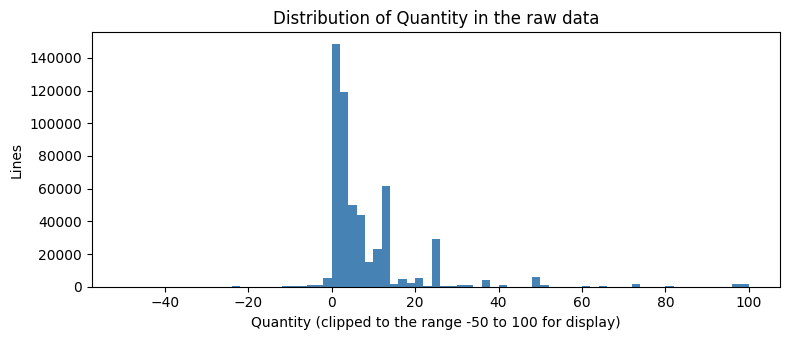

In [46]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(raw_df.loc[raw_df["Quantity"].between(-50, 100), "Quantity"], bins=75, color="steelblue")
ax.set_xlabel("Quantity (clipped to the range -50 to 100 for display)")
ax.set_ylabel("Lines")
ax.set_title("Distribution of Quantity in the raw data")
plt.tight_layout()
plt.show()

## Section 8: Initial Findings

Numbers below come from the code above.

In [47]:
from IPython.display import Markdown, display

top_country = transactions_by_country.index[0]
top_country_share = transactions_by_country["invoices"].iloc[0] / transactions_by_country["invoices"].sum() * 100
busiest_month = monthly_volume.loc[monthly_volume["invoices"].idxmax()]
complete_months = monthly_volume.iloc[:-1]
quietest_month = complete_months.loc[complete_months["invoices"].idxmin()]
partial_month = monthly_volume.iloc[-1]

findings = f"""
**Dataset obtained.** `{excel_path.name}` was extracted from `{zip_path.name}` and loaded into `raw_df` with {len(raw_df):,} rows and {raw_df.shape[1]} columns, covering {raw_df['InvoiceDate'].min():%d %B %Y} to {raw_df['InvoiceDate'].max():%d %B %Y}.

**Scale.** The data holds {invoice_text.nunique():,} invoices, {raw_df['CustomerID'].nunique():,} identified customers, {stock_text.nunique():,} stock codes and {raw_df['Country'].nunique()} countries.

**Data quality problems discovered**

- {int(missing_customer.sum()):,} rows ({missing_customer.mean() * 100:.1f}%) have no CustomerID, and {int(missing_description.sum()):,} rows have no Description.
- {duplicate_row_count:,} rows are exact duplicates of another row.
- {int(cancelled_mask.sum()):,} lines belong to cancelled invoices, and {int((raw_df['Quantity'] < 0).sum()):,} lines in total have a negative quantity.
- {int((raw_df['UnitPrice'] <= 0).sum()):,} lines have a zero or negative unit price.
- {int((~product_pattern).sum()):,} lines use stock codes that are not product numbers, such as postage and manual adjustments.
- InvoiceNo and StockCode contain a mix of numbers and text, and {int((descriptions_per_code > 1).sum()):,} stock codes have more than one description.

**Patterns discovered**

- {top_country} accounts for {top_country_share:.1f}% of all invoices.
- Monthly invoice volume is highest in {busiest_month['month']} ({int(busiest_month['invoices']):,} invoices) and lowest among complete months in {quietest_month['month']} ({int(quietest_month['invoices']):,} invoices). The final month, {partial_month['month']}, is incomplete because the data ends on {raw_df['InvoiceDate'].max():%d %B %Y}.
- Quantity contains extreme positive and negative values that need inspection before any analysis.
"""
display(Markdown(findings))


**Dataset obtained.** `Online Retail.xlsx` was extracted from `online+retail.zip` and loaded into `raw_df` with 541,909 rows and 8 columns, covering 01 December 2010 to 09 December 2011.

**Scale.** The data holds 25,900 invoices, 4,372 identified customers, 4,070 stock codes and 38 countries.

**Data quality problems discovered**

- 135,080 rows (24.9%) have no CustomerID, and 1,454 rows have no Description.
- 5,268 rows are exact duplicates of another row.
- 9,288 lines belong to cancelled invoices, and 10,624 lines in total have a negative quantity.
- 2,517 lines have a zero or negative unit price.
- 2,995 lines use stock codes that are not product numbers, such as postage and manual adjustments.
- InvoiceNo and StockCode contain a mix of numbers and text, and 650 stock codes have more than one description.

**Patterns discovered**

- United Kingdom accounts for 90.7% of all invoices.
- Monthly invoice volume is highest in 2011-11 (3,462 invoices) and lowest among complete months in 2011-02 (1,393 invoices). The final month, 2011-12, is incomplete because the data ends on 09 December 2011.
- Quantity contains extreme positive and negative values that need inspection before any analysis.


# Cleaning and Transformation

Fix the problems found during exploration. `raw_df` stays as it is. All cleaning is done on `clean_df`.

## Section 1: Start From the Raw Data

`clean_df` is a copy of `raw_df`.

In [48]:
pd.set_option("display.float_format", "{:,.2f}".format)

In [49]:
clean_df = raw_df.copy()
print("raw_df rows  :", f"{len(raw_df):,}")
print("clean_df rows:", f"{len(clean_df):,}")

raw_df rows  : 541,909
clean_df rows: 541,909


## Section 2: Data Cleaning

Helper removes rows, prints before/after counts and logs each step.

In [50]:
cleaning_log = []


def remove_rows(frame, remove_mask, step, reason):
    before_rows = len(frame)
    removed = frame[remove_mask]
    kept = frame[~remove_mask]
    cleaning_log.append(
        {"step": step, "before_rows": before_rows, "rows_removed": len(removed), "after_rows": len(kept), "reason": reason}
    )
    print(f"{step}")
    print(f"  Before rows : {before_rows:,}")
    print(f"  Rows removed: {len(removed):,}")
    print(f"  After rows  : {len(kept):,}")
    return kept, removed

### 2.1 Convert data types and standardize text

InvoiceNo and StockCode become text. Trim text and make description and stock code upper case, so one product has one spelling.

In [51]:
dtypes_before = clean_df.dtypes.astype(str).rename("dtype_before")
descriptions_before = clean_df["Description"].copy()
stock_before = clean_df["StockCode"].astype(str).copy()

clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype(str).str.strip()
clean_df["StockCode"] = clean_df["StockCode"].astype(str).str.strip().str.upper()
clean_df["Description"] = (
    clean_df["Description"].str.upper().str.replace(r"\s+", " ", regex=True).str.strip()
)
clean_df["Country"] = clean_df["Country"].str.strip()
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"], errors="coerce")
clean_df["Quantity"] = pd.to_numeric(clean_df["Quantity"], errors="coerce")
clean_df["UnitPrice"] = pd.to_numeric(clean_df["UnitPrice"], errors="coerce")

dtypes_after = clean_df.dtypes.astype(str).rename("dtype_after")
pd.concat([dtypes_before, dtypes_after], axis=1)

,dtype_before,dtype_after
InvoiceNo,object,str
StockCode,object,str
Description,object,object
Quantity,int64,int64
InvoiceDate,datetime64[us],datetime64[us]
UnitPrice,float64,float64
CustomerID,float64,float64
Country,str,str


In [52]:
conversion_checks = pd.DataFrame(
    {
        "check": [
            "Dates that could not be parsed",
            "Quantities that could not be parsed",
            "Unit prices that could not be parsed",
            "Descriptions changed by standardization",
            "StockCodes changed by standardization",
        ],
        "count": [
            int(clean_df["InvoiceDate"].isna().sum()),
            int(clean_df["Quantity"].isna().sum()),
            int(clean_df["UnitPrice"].isna().sum()),
            int((descriptions_before.fillna("") != clean_df["Description"].fillna("")).sum()),
            int((stock_before != clean_df["StockCode"]).sum()),
        ],
    }
)
conversion_checks

,check,count
0,Dates that could not be parsed,0
1,Quantities that could not be parsed,0
2,Unit prices that could not be parsed,0
3,Descriptions changed by standardization,131126
4,StockCodes changed by standardization,1977


In [53]:
changed_descriptions = descriptions_before.fillna("") != clean_df["Description"].fillna("")
pd.DataFrame(
    {"before": descriptions_before[changed_descriptions], "after": clean_df.loc[changed_descriptions, "Description"]}
).head(8)

,before,after
10,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE BEDROOM
13,IVORY KNITTED MUG COSY,IVORY KNITTED MUG COSY
15,BOX OF VINTAGE JIGSAW BLOCKS,BOX OF VINTAGE JIGSAW BLOCKS
27,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE RED
30,STARS GIFT TAPE,STARS GIFT TAPE
31,INFLATABLE POLITICAL GLOBE,INFLATABLE POLITICAL GLOBE
32,VINTAGE HEADS AND TAILS CARD GAME,VINTAGE HEADS AND TAILS CARD GAME
33,SET/2 RED RETROSPOT TEA TOWELS,SET/2 RED RETROSPOT TEA TOWELS


### 2.2 Remove duplicate records

Drop identical rows, keep the first. Count can be higher than the raw count because cleaning the text exposes more duplicates.

In [54]:
raw_duplicates = int(raw_df.duplicated().sum())
clean_df, removed_duplicates = remove_rows(
    clean_df, clean_df.duplicated(keep="first"), "Remove duplicate rows", "Identical rows repeat the same sale"
)
print("  Exact duplicates found in the raw data:", f"{raw_duplicates:,}")
removed_duplicates.head()

Remove duplicate rows
  Before rows : 541,909
  Rows removed: 5,268
  After rows  : 536,641
  Exact duplicates found in the raw data: 5,268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,"17,920.00",United Kingdom


### 2.3 Separate cancelled invoices

Invoices starting with C are cancellations. Move them to `cancelled_df`.

In [55]:
cancel_mask = clean_df["InvoiceNo"].str.startswith("C")
clean_df, cancelled_df = remove_rows(
    clean_df, cancel_mask, "Separate cancelled invoices", "Cancellations are not sales and carry negative quantities"
)
cancelled_df = cancelled_df.assign(Revenue=(cancelled_df["Quantity"] * cancelled_df["UnitPrice"]).round(2))
cancelled_df.head()

Separate cancelled invoices
  Before rows : 536,641
  Rows removed: 9,251
  After rows  : 527,390


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
141,C536379,D,DISCOUNT,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom,-6.96


### 2.4 Remove invalid quantities

In [56]:
clean_df, invalid_quantity = remove_rows(
    clean_df, clean_df["Quantity"] <= 0, "Remove zero or negative quantities", "Sales must have a positive quantity"
)
invalid_quantity.head()

Remove zero or negative quantities
  Before rows : 527,390
  Rows removed: 1,336
  After rows  : 526,054


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.00,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.00,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.00,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.00,NaN,United Kingdom


### 2.5 Remove invalid prices

In [57]:
clean_df, invalid_price = remove_rows(
    clean_df, clean_df["UnitPrice"] <= 0, "Remove zero or negative prices", "A sale must have a positive price"
)
invalid_price.head()

Remove zero or negative prices
  Before rows : 526,054
  Rows removed: 1,176
  After rows  : 524,878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.00,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.00,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.00,NaN,United Kingdom


### 2.6 Remove non-product stock codes

POST, M, BANK CHARGES etc. are not products. Product codes start with 5 digits, drop the rest.

In [58]:
non_product_mask = ~clean_df["StockCode"].str.match(r"^\d{5}")
non_product_summary = (
    clean_df[non_product_mask].groupby("StockCode").agg(lines=("StockCode", "size"), example=("Description", "first")).sort_values("lines", ascending=False)
)
non_product_summary

,lines,example
StockCode,,
POST,1126,POSTAGE
DOT,706,DOTCOM POSTAGE
M,317,MANUAL
C2,141,CARRIAGE
DCGSSGIRL,13,GIRLS PARTY BAG
BANK CHARGES,12,BANK CHARGES
DCGSSBOY,11,BOYS PARTY BAG
GIFT_0001_20,9,DOTCOMGIFTSHOP GIFT VOUCHER £20.00
GIFT_0001_10,8,DOTCOMGIFTSHOP GIFT VOUCHER £10.00


In [59]:
clean_df, non_product_rows = remove_rows(
    clean_df, non_product_mask, "Remove non-product stock codes", "Postage, fees and manual entries are not products"
)

Remove non-product stock codes
  Before rows : 524,878
  Rows removed: 2,374
  After rows  : 522,504


### 2.7 Handle missing CustomerID

Orders need a customer, so rows with no CustomerID are dropped. Biggest loss of rows.

In [60]:
clean_df, missing_customer_rows = remove_rows(
    clean_df,
    clean_df["CustomerID"].isna(),
    "Remove rows without CustomerID",
    "Orders must reference a customer in the relational model",
)
missing_customer_rows.head()

Remove rows without CustomerID
  Before rows : 522,504
  Rows removed: 131,354
  After rows  : 391,150


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom


In [61]:
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")
clean_df["CustomerID"].dtype

dtype('int64')

### 2.7b Remove sales that were fully reversed

Some big orders were cancelled right after. Match each cancellation to an earlier sale (same customer, product, quantity) and drop that sale. Partial returns are not matched.

In [62]:
sale_keys = clean_df[["CustomerID", "StockCode", "Quantity", "InvoiceDate"]].copy()
sale_keys["row_id"] = sale_keys.index
sale_keys = sale_keys.sort_values(["InvoiceDate", "row_id"])
sale_keys["occurrence"] = sale_keys.groupby(["CustomerID", "StockCode", "Quantity"]).cumcount()

cancel_keys = cancelled_df.dropna(subset=["CustomerID"]).copy()
cancel_keys["CustomerID"] = cancel_keys["CustomerID"].astype("int64")
cancel_keys["Quantity"] = -cancel_keys["Quantity"]
cancel_keys = cancel_keys.sort_values("InvoiceDate")
cancel_keys["occurrence"] = cancel_keys.groupby(["CustomerID", "StockCode", "Quantity"]).cumcount()
cancel_keys = cancel_keys.rename(columns={"InvoiceDate": "cancel_date"})

matched_pairs = sale_keys.merge(
    cancel_keys[["CustomerID", "StockCode", "Quantity", "occurrence", "cancel_date"]],
    on=["CustomerID", "StockCode", "Quantity", "occurrence"],
    how="inner",
)
matched_pairs = matched_pairs[matched_pairs["InvoiceDate"] <= matched_pairs["cancel_date"]]
print("Cancelled lines available for matching:", f"{len(cancel_keys):,}")
print("Cancelled lines matched to an earlier sale:", f"{len(matched_pairs):,}")
matched_pairs.sort_values("Quantity", ascending=False).head(5)

Cancelled lines available for matching: 8,872
Cancelled lines matched to an earlier sale: 2,797


,CustomerID,StockCode,Quantity,InvoiceDate,row_id,occurrence,cancel_date
3081,16446,23843,80995,2011-12-09 09:15:00,540421,0,2011-12-09 09:27:00
452,12346,23166,74215,2011-01-18 10:01:00,61619,0,2011-01-18 10:17:00
387,15749,21108,3114,2011-01-11 12:55:00,52711,0,2011-04-18 13:08:00
386,15749,21175,2000,2011-01-11 12:55:00,52710,0,2011-04-18 13:08:00
385,15749,85123A,1930,2011-01-11 12:55:00,52709,0,2011-04-18 13:08:00


In [63]:
clean_df, reversed_sales_df = remove_rows(
    clean_df,
    clean_df.index.isin(matched_pairs["row_id"]),
    "Remove sales fully reversed by a cancellation",
    "A sale cancelled in full has no net revenue",
)
reversed_sales_df = reversed_sales_df.assign(Revenue=(reversed_sales_df["Quantity"] * reversed_sales_df["UnitPrice"]).round(2))
reversed_sales_df.sort_values("Revenue", ascending=False).head()

Remove sales fully reversed by a cancellation
  Before rows : 391,150
  Rows removed: 2,797
  After rows  : 388,353


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,"168,469.60"
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,"77,183.60"
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,"6,539.40"
52709,540815,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,2011-01-11 12:55:00,2.55,15749,United Kingdom,"4,921.50"
52772,540818,48185,DOORMAT FAIRY CAKE,670,2011-01-11 12:57:00,6.75,15749,United Kingdom,"4,522.50"


### 2.8 Handle missing descriptions

Fill from the same stock code. Drop any that are still missing.

In [64]:
missing_before = int(clean_df["Description"].isna().sum())
known_descriptions = clean_df.dropna(subset=["Description"]).groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
clean_df["Description"] = clean_df["Description"].fillna(clean_df["StockCode"].map(known_descriptions))
missing_after_fill = int(clean_df["Description"].isna().sum())
print("Missing descriptions before filling:", missing_before)
print("Missing descriptions after filling :", missing_after_fill)

Missing descriptions before filling: 0
Missing descriptions after filling : 0


In [65]:
clean_df, missing_description_rows = remove_rows(
    clean_df, clean_df["Description"].isna(), "Remove rows with unrecoverable description", "No product name is available"
)

Remove rows with unrecoverable description
  Before rows : 388,353
  Rows removed: 0
  After rows  : 388,353


## Section 3: Cleaning Progress

In [66]:
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.loc[len(cleaning_log_df)] = {
    "step": "Total",
    "before_rows": len(raw_df),
    "rows_removed": len(raw_df) - len(clean_df),
    "after_rows": len(clean_df),
    "reason": "Raw rows compared with rows kept",
}
cleaning_log_df

,step,before_rows,rows_removed,after_rows,reason
0,Remove duplicate rows,541909,5268,536641,Identical rows repeat the same sale
1,Separate cancelled invoices,536641,9251,527390,Cancellations are not sales and carry negative...
2,Remove zero or negative quantities,527390,1336,526054,Sales must have a positive quantity
3,Remove zero or negative prices,526054,1176,524878,A sale must have a positive price
4,Remove non-product stock codes,524878,2374,522504,"Postage, fees and manual entries are not products"
5,Remove rows without CustomerID,522504,131354,391150,Orders must reference a customer in the relati...
6,Remove sales fully reversed by a cancellation,391150,2797,388353,A sale cancelled in full has no net revenue
7,Remove rows with unrecoverable description,388353,0,388353,No product name is available
8,Total,541909,153556,388353,Raw rows compared with rows kept


In [67]:
steps_only = cleaning_log_df[cleaning_log_df["step"] != "Total"]
fig = px.bar(
    steps_only,
    x="step",
    y="rows_removed",
    title="Rows removed at each cleaning step",
    labels={"rows_removed": "Rows removed", "step": "Cleaning step"},
)
fig.show()

In [68]:
comparison = pd.DataFrame(
    {
        "measure": ["Rows", "Invoices", "Customers", "Stock codes", "Countries"],
        "raw_df": [
            len(raw_df),
            raw_df["InvoiceNo"].astype(str).nunique(),
            raw_df["CustomerID"].nunique(),
            raw_df["StockCode"].astype(str).nunique(),
            raw_df["Country"].nunique(),
        ],
        "clean_df": [
            len(clean_df),
            clean_df["InvoiceNo"].nunique(),
            clean_df["CustomerID"].nunique(),
            clean_df["StockCode"].nunique(),
            clean_df["Country"].nunique(),
        ],
    }
)
comparison["retained_percent"] = (comparison["clean_df"] / comparison["raw_df"] * 100).round(1)
comparison

,measure,raw_df,clean_df,retained_percent
0,Rows,541909,388353,71.70
1,Invoices,25900,18325,70.80
2,Customers,4372,4324,98.90
3,Stock codes,4070,3646,89.60
4,Countries,38,37,97.40


In [69]:
issue_recheck = pd.DataFrame(
    {
        "check": [
            "Missing values (all columns)",
            "Duplicate rows",
            "Quantity of zero or below",
            "UnitPrice of zero or below",
            "InvoiceNo starting with C",
            "StockCode not starting with a 5-digit number",
        ],
        "raw_df": [
            int(raw_df.isna().sum().sum()),
            int(raw_df.duplicated().sum()),
            int((raw_df["Quantity"] <= 0).sum()),
            int((raw_df["UnitPrice"] <= 0).sum()),
            int(raw_df["InvoiceNo"].astype(str).str.startswith("C").sum()),
            int((~raw_df["StockCode"].astype(str).str.match(r"^\d{5}")).sum()),
        ],
        "clean_df": [
            int(clean_df.isna().sum().sum()),
            int(clean_df.duplicated().sum()),
            int((clean_df["Quantity"] <= 0).sum()),
            int((clean_df["UnitPrice"] <= 0).sum()),
            int(clean_df["InvoiceNo"].str.startswith("C").sum()),
            int((~clean_df["StockCode"].str.match(r"^\d{5}")).sum()),
        ],
    }
)
issue_recheck

,check,raw_df,clean_df
0,Missing values (all columns),136534,0
1,Duplicate rows,5268,0
2,Quantity of zero or below,10624,0
3,UnitPrice of zero or below,2517,0
4,InvoiceNo starting with C,9288,0
5,StockCode not starting with a 5-digit number,2995,0


In [70]:
print("raw_df still has its original shape:", raw_df.shape)
print("Cancelled invoices stored separately:", f"{len(cancelled_df):,}", "lines")
clean_df.head()

raw_df still has its original shape: (541909, 8)
Cancelled invoices stored separately: 9,251 lines


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## Section 4: Feature Engineering

Revenue = Quantity x UnitPrice. Add year, month, day, weekday and hour fields.

In [71]:
clean_df["Revenue"] = (clean_df["Quantity"] * clean_df["UnitPrice"]).round(2)
clean_df["Year"] = clean_df["InvoiceDate"].dt.year
clean_df["Month"] = clean_df["InvoiceDate"].dt.month
clean_df["MonthName"] = clean_df["InvoiceDate"].dt.month_name()
clean_df["Day"] = clean_df["InvoiceDate"].dt.day
clean_df["Weekday"] = clean_df["InvoiceDate"].dt.day_name()
clean_df["Hour"] = clean_df["InvoiceDate"].dt.hour
clean_df["YearMonth"] = clean_df["InvoiceDate"].dt.strftime("%Y-%m")
clean_df[["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Year", "Month", "MonthName", "Day", "Weekday", "Hour", "YearMonth"]].head(10)

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue,Year,Month,MonthName,Day,Weekday,Hour,YearMonth
0,536365,2010-12-01 08:26:00,6,2.55,15.30,2010,12,December,1,Wednesday,8,2010-12
1,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
2,536365,2010-12-01 08:26:00,8,2.75,22.00,2010,12,December,1,Wednesday,8,2010-12
3,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
4,536365,2010-12-01 08:26:00,6,3.39,20.34,2010,12,December,1,Wednesday,8,2010-12
5,536365,2010-12-01 08:26:00,2,7.65,15.30,2010,12,December,1,Wednesday,8,2010-12
6,536365,2010-12-01 08:26:00,6,4.25,25.50,2010,12,December,1,Wednesday,8,2010-12
7,536366,2010-12-01 08:28:00,6,1.85,11.10,2010,12,December,1,Wednesday,8,2010-12
9,536367,2010-12-01 08:34:00,32,1.69,54.08,2010,12,December,1,Wednesday,8,2010-12
10,536367,2010-12-01 08:34:00,6,2.10,12.60,2010,12,December,1,Wednesday,8,2010-12


In [72]:
print("Columns before feature engineering:", len(raw_df.columns))
print("Columns after feature engineering :", len(clean_df.columns))
print("Total revenue in clean_df:", f"{clean_df['Revenue'].sum():,.2f}")
clean_df[["Quantity", "UnitPrice", "Revenue"]].describe()

Columns before feature engineering: 8
Columns after feature engineering : 16
Total revenue in clean_df: 8,349,645.02


,Quantity,UnitPrice,Revenue
count,"388,353.00","388,353.00","388,353.00"
mean,12.66,2.86,21.50
std,42.18,4.12,92.67
min,1.00,0.04,0.06
25%,2.00,1.25,4.95
50%,6.00,1.95,11.90
75%,12.00,3.75,19.80
max,"4,800.00",649.50,"38,970.00"


In [73]:
clean_df.groupby("YearMonth")["Revenue"].sum().round(2).to_frame("revenue")

,revenue
YearMonth,
2010-12,"554,230.92"
2011-01,"454,888.11"
2011-02,"438,390.02"
2011-03,"573,294.62"
2011-04,"450,140.05"
2011-05,"652,185.47"
2011-06,"644,183.90"
2011-07,"582,273.78"
2011-08,"630,531.59"


## Section 5: Relational Data Preparation

Split the clean data into 4 DataFrames: customers, products, orders and order details.

| DataFrame | Meaning | Primary key |
|---|---|---|
| `customers_df` | One row per customer | `customer_id` |
| `products_df` | One row per stock code | `product_id` |
| `orders_df` | One row per invoice | `order_id` |
| `order_details_df` | One row per invoice line | `order_detail_id` |

`customer_id` and `order_id` come from the data. `product_id` and `order_detail_id` are numbered after sorting, so they are the same every run.

### 5.1 customers_df

In [74]:
country_counts = (
    clean_df.groupby(["CustomerID", "Country"]).size().reset_index(name="lines")
    .sort_values(["CustomerID", "lines", "Country"], ascending=[True, False, True])
)
customers_with_several_countries = int((country_counts.groupby("CustomerID").size() > 1).sum())

customers_df = (
    country_counts.drop_duplicates("CustomerID")[["CustomerID", "Country"]]
    .rename(columns={"CustomerID": "customer_id", "Country": "country"})
    .reset_index(drop=True)
)
print("Customers with lines under more than one country:", customers_with_several_countries, "(most frequent country is kept)")
print("customers_df shape:", customers_df.shape)
customers_df.head()

Customers with lines under more than one country: 8 (most frequent country is kept)
customers_df shape: (4324, 2)


,customer_id,country
0,12347,Iceland
1,12348,Finland
2,12349,Italy
3,12350,Norway
4,12352,Norway


### 5.2 products_df

A stock code can have many descriptions and prices. Use the most common description and the median price.

In [75]:
description_counts = (
    clean_df.groupby(["StockCode", "Description"]).size().reset_index(name="lines")
    .sort_values(["StockCode", "lines", "Description"], ascending=[True, False, True])
    .drop_duplicates("StockCode")[["StockCode", "Description"]]
)
median_price = clean_df.groupby("StockCode")["UnitPrice"].median().round(2).rename("unit_price").reset_index()

products_df = description_counts.merge(median_price, on="StockCode").sort_values("StockCode").reset_index(drop=True)
products_df.insert(0, "product_id", range(1, len(products_df) + 1))
products_df = products_df.rename(columns={"StockCode": "stock_code", "Description": "description"})
print("products_df shape:", products_df.shape)
products_df.head()

products_df shape: (3646, 4)


,product_id,stock_code,description,unit_price
0,1,10002,INFLATABLE POLITICAL GLOBE,0.85
1,2,10080,GROOVY CACTUS INFLATABLE,0.39
2,3,10120,DOGGY RUBBER,0.21
3,4,10123C,HEARTS WRAPPING TAPE,0.65
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE,0.42


### 5.3 orders_df

In [76]:
invoice_checks = clean_df.groupby("InvoiceNo").agg(customers=("CustomerID", "nunique"), timestamps=("InvoiceDate", "nunique"))
print("Invoices with more than one customer :", int((invoice_checks["customers"] > 1).sum()))
print("Invoices with more than one timestamp:", int((invoice_checks["timestamps"] > 1).sum()), "(the earliest timestamp is used)")
print("All invoice numbers are numeric       :", bool(clean_df["InvoiceNo"].str.isdigit().all()))

Invoices with more than one customer : 0
Invoices with more than one timestamp: 30 (the earliest timestamp is used)
All invoice numbers are numeric       : True


In [77]:
orders_df = (
    clean_df.groupby("InvoiceNo")
    .agg(customer_id=("CustomerID", "first"), order_date=("InvoiceDate", "min"))
    .reset_index()
)
orders_df["order_id"] = orders_df["InvoiceNo"].astype("int64")
orders_df = orders_df[["order_id", "customer_id", "order_date"]].sort_values("order_id").reset_index(drop=True)
print("orders_df shape:", orders_df.shape)
orders_df.head()

orders_df shape: (18325, 3)


,order_id,customer_id,order_date
0,536365,17850,2010-12-01 08:26:00
1,536366,17850,2010-12-01 08:28:00
2,536367,13047,2010-12-01 08:34:00
3,536368,13047,2010-12-01 08:34:00
4,536369,13047,2010-12-01 08:35:00


### 5.4 order_details_df

In [78]:
product_lookup = products_df.set_index("stock_code")["product_id"]
sorted_lines = clean_df.sort_values(
    ["InvoiceDate", "InvoiceNo", "StockCode", "Quantity", "UnitPrice"], kind="stable"
).reset_index(drop=True)

order_details_df = pd.DataFrame(
    {
        "order_detail_id": np.arange(1, len(sorted_lines) + 1),
        "order_id": sorted_lines["InvoiceNo"].astype("int64"),
        "product_id": sorted_lines["StockCode"].map(product_lookup).astype("int64"),
        "quantity": sorted_lines["Quantity"].astype("int64"),
        "unit_price": sorted_lines["UnitPrice"].astype("float64"),
        "revenue": sorted_lines["Revenue"].astype("float64"),
    }
)
print("order_details_df shape:", order_details_df.shape)
order_details_df.head()

order_details_df shape: (388353, 6)


,order_detail_id,order_id,product_id,quantity,unit_price,revenue
0,1,536365,750,6,4.25,25.50
1,2,536365,1600,2,7.65,15.30
2,3,536365,2641,6,3.39,20.34
3,4,536365,2792,6,3.39,20.34
4,5,536365,2793,6,3.39,20.34


In [79]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "rows": [len(customers_df), len(products_df), len(orders_df), len(order_details_df)],
        "columns": [", ".join(frame.columns) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,rows,columns
0,customers_df,4324,"customer_id, country"
1,products_df,3646,"product_id, stock_code, description, unit_price"
2,orders_df,18325,"order_id, customer_id, order_date"
3,order_details_df,388353,"order_detail_id, order_id, product_id, quantit..."


## Section 6: Data Validation

Each check gives PASS or FAIL. Stops if anything fails.

In [80]:
validation_results = []


def record_check(area, check, passed, detail):
    validation_results.append({"area": area, "check": check, "result": "PASS" if passed else "FAIL", "detail": detail})


record_check("Primary key", "customers_df.customer_id is unique", customers_df["customer_id"].is_unique, f"{len(customers_df):,} rows")
record_check("Primary key", "products_df.product_id is unique", products_df["product_id"].is_unique, f"{len(products_df):,} rows")
record_check("Primary key", "products_df.stock_code is unique", products_df["stock_code"].is_unique, f"{len(products_df):,} rows")
record_check("Primary key", "orders_df.order_id is unique", orders_df["order_id"].is_unique, f"{len(orders_df):,} rows")
record_check("Primary key", "order_details_df.order_detail_id is unique", order_details_df["order_detail_id"].is_unique, f"{len(order_details_df):,} rows")

orphan_orders_customer = int((~orders_df["customer_id"].isin(customers_df["customer_id"])).sum())
orphan_details_order = int((~order_details_df["order_id"].isin(orders_df["order_id"])).sum())
orphan_details_product = int((~order_details_df["product_id"].isin(products_df["product_id"])).sum())
record_check("Foreign key", "orders.customer_id exists in customers", orphan_orders_customer == 0, f"{orphan_orders_customer} orphans")
record_check("Foreign key", "order_details.order_id exists in orders", orphan_details_order == 0, f"{orphan_details_order} orphans")
record_check("Foreign key", "order_details.product_id exists in products", orphan_details_product == 0, f"{orphan_details_product} orphans")

for name, frame in [("customers_df", customers_df), ("products_df", products_df), ("orders_df", orders_df), ("order_details_df", order_details_df)]:
    record_check("Missing values", f"{name} has no missing values", int(frame.isna().sum().sum()) == 0, f"{int(frame.isna().sum().sum())} missing")

pd.DataFrame(validation_results)

,area,check,result,detail
0,Primary key,customers_df.customer_id is unique,PASS,"4,324 rows"
1,Primary key,products_df.product_id is unique,PASS,"3,646 rows"
2,Primary key,products_df.stock_code is unique,PASS,"3,646 rows"
3,Primary key,orders_df.order_id is unique,PASS,"18,325 rows"
4,Primary key,order_details_df.order_detail_id is unique,PASS,"388,353 rows"
5,Foreign key,orders.customer_id exists in customers,PASS,0 orphans
6,Foreign key,order_details.order_id exists in orders,PASS,0 orphans
7,Foreign key,order_details.product_id exists in products,PASS,0 orphans
8,Missing values,customers_df has no missing values,PASS,0 missing
9,Missing values,products_df has no missing values,PASS,0 missing


In [81]:
recomputed_revenue = (order_details_df["quantity"] * order_details_df["unit_price"]).round(2)
largest_difference = float((recomputed_revenue - order_details_df["revenue"]).abs().max())
revenue_difference = abs(order_details_df["revenue"].sum() - clean_df["Revenue"].sum())

record_check("Revenue", "revenue equals quantity x unit_price on every line", largest_difference < 0.005, f"largest difference {largest_difference:.4f}")
record_check("Revenue", "order_details revenue total equals clean_df revenue total", revenue_difference < 0.01, f"{order_details_df['revenue'].sum():,.2f}")
record_check("Values", "all quantities are positive", bool((order_details_df["quantity"] > 0).all()), "quantity > 0")
record_check("Values", "all unit prices are positive", bool((order_details_df["unit_price"] > 0).all()), "unit_price > 0")
record_check("Values", "all revenue values are positive", bool((order_details_df["revenue"] > 0).all()), "revenue > 0")
record_check("Duplicates", "no duplicated lines in clean_df", int(clean_df.duplicated().sum()) == 0, f"{int(clean_df.duplicated().sum())} duplicates")
record_check("Row counts", "order_details_df rows equal clean_df rows", len(order_details_df) == len(clean_df), f"{len(order_details_df):,} rows")
record_check("Row counts", "orders_df rows equal distinct invoices", len(orders_df) == clean_df["InvoiceNo"].nunique(), f"{len(orders_df):,} orders")
record_check("Row counts", "customers_df rows equal distinct customers", len(customers_df) == clean_df["CustomerID"].nunique(), f"{len(customers_df):,} customers")
record_check("Row counts", "products_df rows equal distinct stock codes", len(products_df) == clean_df["StockCode"].nunique(), f"{len(products_df):,} products")
cleaning_validation_df = pd.DataFrame(validation_results)
cleaning_validation_df

,area,check,result,detail
0,Primary key,customers_df.customer_id is unique,PASS,"4,324 rows"
1,Primary key,products_df.product_id is unique,PASS,"3,646 rows"
2,Primary key,products_df.stock_code is unique,PASS,"3,646 rows"
3,Primary key,orders_df.order_id is unique,PASS,"18,325 rows"
4,Primary key,order_details_df.order_detail_id is unique,PASS,"388,353 rows"
5,Foreign key,orders.customer_id exists in customers,PASS,0 orphans
6,Foreign key,order_details.order_id exists in orders,PASS,0 orphans
7,Foreign key,order_details.product_id exists in products,PASS,0 orphans
8,Missing values,customers_df has no missing values,PASS,0 missing
9,Missing values,products_df has no missing values,PASS,0 missing


In [82]:
pd.DataFrame(
    {
        "dataframe": ["customers_df", "products_df", "orders_df", "order_details_df"],
        "dtypes": [", ".join(f"{col}:{dtype}" for col, dtype in frame.dtypes.astype(str).items()) for frame in [customers_df, products_df, orders_df, order_details_df]],
    }
)

,dataframe,dtypes
0,customers_df,"customer_id:int64, country:str"
1,products_df,"product_id:int64, stock_code:str, description:..."
2,orders_df,"order_id:int64, customer_id:int64, order_date:..."
3,order_details_df,"order_detail_id:int64, order_id:int64, product..."


In [83]:
failed_checks = cleaning_validation_df[cleaning_validation_df["result"] == "FAIL"]
assert failed_checks.empty, failed_checks
print("Checks passed:", int((cleaning_validation_df["result"] == "PASS").sum()), "of", len(cleaning_validation_df))

Checks passed: 22 of 22


## Section 7: Cleaning Summary

In [84]:
removed_total = len(raw_df) - len(clean_df)
biggest_step = cleaning_log_df[cleaning_log_df["step"] != "Total"].sort_values("rows_removed", ascending=False).iloc[0]

summary = f"""
**What was wrong.** The raw data had {int(raw_df['CustomerID'].isna().sum()):,} rows without a CustomerID, {raw_duplicates:,} exact duplicate rows, {len(cancelled_df):,} cancelled invoice lines, zero or negative quantities and prices, non-product stock codes and mixed data types. {len(reversed_sales_df):,} sales lines worth {reversed_sales_df['Revenue'].sum():,.2f} were cancelled in full by a later invoice.

**What was cleaned.** {removed_total:,} of {len(raw_df):,} rows ({removed_total / len(raw_df) * 100:.1f}%) were removed or separated, leaving {len(clean_df):,} valid sales lines. The largest step was "{biggest_step['step']}" with {int(biggest_step['rows_removed']):,} rows.

**Why it was cleaned.** Sales analysis needs positive quantities and prices, real products and a known customer. Cancellations were kept in `cancelled_df` and fully reversed sales in `reversed_sales_df` because they describe returned business.

**What was transformed.** Text was standardized, dates and numbers were typed correctly, and `Revenue`, `Year`, `Month`, `MonthName`, `Day`, `Weekday`, `Hour` and `YearMonth` were created. Total clean revenue is {clean_df['Revenue'].sum():,.2f}.

**Relational tables created.**

- customers_df: {len(customers_df):,} rows
- products_df: {len(products_df):,} rows
- orders_df: {len(orders_df):,} rows
- order_details_df: {len(order_details_df):,} rows

All {len(cleaning_validation_df)} validation checks passed.
"""
display(Markdown(summary))


**What was wrong.** The raw data had 135,080 rows without a CustomerID, 5,268 exact duplicate rows, 9,251 cancelled invoice lines, zero or negative quantities and prices, non-product stock codes and mixed data types. 2,797 sales lines worth 387,582.62 were cancelled in full by a later invoice.

**What was cleaned.** 153,556 of 541,909 rows (28.3%) were removed or separated, leaving 388,353 valid sales lines. The largest step was "Remove rows without CustomerID" with 131,354 rows.

**Why it was cleaned.** Sales analysis needs positive quantities and prices, real products and a known customer. Cancellations were kept in `cancelled_df` and fully reversed sales in `reversed_sales_df` because they describe returned business.

**What was transformed.** Text was standardized, dates and numbers were typed correctly, and `Revenue`, `Year`, `Month`, `MonthName`, `Day`, `Weekday`, `Hour` and `YearMonth` were created. Total clean revenue is 8,349,645.02.

**Relational tables created.**

- customers_df: 4,324 rows
- products_df: 3,646 rows
- orders_df: 18,325 rows
- order_details_df: 388,353 rows

All 22 validation checks passed.


**End state**

```text
Raw Data
↓
Cleaned Data
↓
Transformed Data
↓
Relational DataFrames
```